<a href="https://colab.research.google.com/github/erikomarcamarena0409-source/detective-de-senales/blob/main/detector_de_senales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.model_selection import train_test_split

# --- 1.1. Configurar el entorno ---
np.random.seed(42)
print("-> 1.1 Entorno configurado y librerías importadas.")

# --- 1.2. Definir los parámetros de la señal ---
f_s = 10000       # Frecuencia de muestreo (Hz)
f_c = 1000        # Frecuencia portadora (Hz)
R_s = 100         # Tasa de símbolos (Baudios)
samples_per_symbol = int(f_s / R_s)
print("-> 1.2 Parámetros de la señal definidos.")

# --- 1.3. Programar los generadores de señales ---
def generar_datos_aleatorios(n):
    return np.random.randint(0, 2, n)

def modular_ASK(bits, f_s, f_c, sps):
    senal_portadora = np.cos(2 * np.pi * f_c * np.arange(len(bits) * sps) / f_s)
    simbolos_repetidos = np.repeat(bits, sps)
    return simbolos_repetidos * senal_portadora

def modular_FSK(bits, f_s, f_c, sps, delta_f=200):
    senal_fsk = []
    for bit in bits:
        f_actual = f_c + delta_f if bit == 1 else f_c - delta_f
        t = np.linspace(0, sps / f_s, sps, endpoint=False)
        portadora = np.cos(2 * np.pi * f_actual * t)
        senal_fsk.extend(portadora)
    return np.array(senal_fsk)

def modular_PSK(bits, f_s, f_c, sps):
    senal_psk = []
    for bit in bits:
        fase = 0 if bit == 1 else np.pi
        t = np.linspace(0, sps / f_s, sps, endpoint=False)
        portadora = np.cos(2 * np.pi * f_c * t + fase)
        senal_psk.extend(portadora)
    return np.array(senal_psk)

def modular_16QAM(s16, f_s, f_c, sps):
    senal_qam = []
    for simbolo in s16:
        i_val = ((simbolo >> 2) & 0x03) - 1.5
        q_val = (simbolo & 0x03) - 1.5
        t = np.linspace(0, sps / f_s, sps, endpoint=False)
        port_i = np.cos(2 * np.pi * f_c * t)
        port_q = -np.sin(2 * np.pi * f_c * t)
        form_onda = i_val * port_i + q_val * port_q
        senal_qam.extend(form_onda)
    return np.array(senal_qam)
print("-> 1.3 Funciones de generadores de señales programadas (ASK, FSK, PSK, QAM).")

# --- 1.5. Añadir Ruido (AWGN) ---
def agregar_awgn(senal, snr_db):
    potencia_senal = np.mean(senal ** 2)
    snr_lineal = 10 ** (snr_db / 10.0)
    potencia_ruido = potencia_senal / snr_lineal
    ruido = np.random.normal(0, np.sqrt(potencia_ruido), len(senal))
    return senal + ruido

def asegurar_longitud(sig, objetivo):
    if len(sig) > objetivo:
        return sig[:objetivo]
    elif len(sig) < objetivo:
        return np.pad(sig, (0, objetivo - len(sig)), 'constant')
    return sig

# --- 1.4. Generar el conjunto de datos masivo ---
print("-> 1.4 y 1.5 Generando el dataset sintético con ruido AWGN...")
num_muestras_por_clase = 1000
longitud_objetivo = 2000
niveles_snr = [0, 5, 10, 15, 20]

X = []
y = []

for snr in niveles_snr:
    for _ in range(num_muestras_por_clase // len(niveles_snr)):
        # ASK (Clase 0)
        sig = modular_ASK(generar_datos_aleatorios(20), f_s, f_c, samples_per_symbol)
        X.append(asegurar_longitud(sig, longitud_objetivo) + agregar_awgn(np.zeros(longitud_objetivo), snr)[:longitud_objetivo])
        y.append(0)
        # FSK (Clase 1)
        sig = modular_FSK(generar_datos_aleatorios(20), f_s, f_c, samples_per_symbol)
        X.append(asegurar_longitud(sig, longitud_objetivo) + agregar_awgn(np.zeros(longitud_objetivo), snr)[:longitud_objetivo])
        y.append(1)
        # PSK (Clase 2)
        sig = modular_PSK(generar_datos_aleatorios(20), f_s, f_c, samples_per_symbol)
        X.append(asegurar_longitud(sig, longitud_objetivo) + agregar_awgn(np.zeros(longitud_objetivo), snr)[:longitud_objetivo])
        y.append(2)
        # QAM (Clase 3)
        sig = modular_16QAM(np.random.randint(0, 16, 10), f_s, f_c, samples_per_symbol)
        X.append(asegurar_longitud(sig, longitud_objetivo) + agregar_awgn(np.zeros(longitud_objetivo), snr)[:longitud_objetivo])
        y.append(3)

X = np.array(X)
y = np.array(y)

# --- 1.6. Separación de datos (Entrenamiento 80% / Prueba 20%) ---
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print(f"-> 1.6 Datos separados con éxito. X_train: {X_train.shape}, X_test: {X_test.shape}")

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout

print("\n--- INICIANDO FASE 2 ---")

# --- 2.2. Diseñar el modelo (CNN 1D) ---
model = Sequential([
    Conv1D(filters=32, kernel_size=3, activation='relu', input_shape=(2000, 1)),
    MaxPooling1D(pool_size=2),
    Conv1D(filters=64, kernel_size=3, activation='relu'),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(4, activation='softmax') # 4 salidas para ASK, FSK, PSK, QAM
])
print("-> 2.2 Arquitectura del modelo CNN 1D diseñada.")

# --- 2.3. Compilar el modelo ---
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
print("-> 2.3 Modelo compilado (Optimizador: Adam).")

# Mostrar resumen de capas
model.summary()

# --- 2.4. Entrenar el modelo ---
print("\n-> 2.4 Iniciando entrenamiento del modelo (.fit)...")
historial = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_test, y_test)
)

# --- 2.5. Guardar el modelo ---
model.save('detector_modulaciones_cnn.keras')
print("\n-> 2.5 ¡Modelo entrenado y guardado exitosamente como 'detector_modulaciones_cnn.keras'!")



-> 1.1 Entorno configurado y librerías importadas.
-> 1.2 Parámetros de la señal definidos.
-> 1.3 Funciones de generadores de señales programadas (ASK, FSK, PSK, QAM).
-> 1.4 y 1.5 Generando el dataset sintético con ruido AWGN...
-> 1.6 Datos separados con éxito. X_train: (3200, 2000), X_test: (800, 2000)

--- INICIANDO FASE 2 ---
-> 2.2 Arquitectura del modelo CNN 1D diseñada.
-> 2.3 Modelo compilado (Optimizador: Adam).


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 1998, 32)       │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 999, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 997, 64)        │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 498, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 31872)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     2,039,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,046,468 (7.81 MB)

 Trainable params: 2,046,468 (7.81 MB)

 Non-trainable params: 0 (0.00 B)


-> 2.4 Iniciando entrenamiento del modelo (.fit)...
Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 13s 114ms/step - accuracy: 0.9753 - loss: 0.0628 - val_accuracy: 1.0000 - val_loss: 4.9153e-06
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - accuracy: 0.9984 - loss: 0.0058 - val_accuracy: 1.0000 - val_loss: 1.1271e-04
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 22s 125ms/step - accuracy: 1.0000 - loss: 4.4293e-04 - val_accuracy: 1.0000 - val_loss: 2.3125e-06
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 19s 115ms/step - accuracy: 0.9978 - loss: 0.0071 - val_accuracy: 1.0000 - val_loss: 8.1887e-05
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - accuracy: 0.9997 - loss: 0.0021 - val_accuracy: 1.0000 - val_loss: 2.9290e-06
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 21s 119ms/step - accuracy: 0.9997 - loss: 0.0010 - val_accuracy: 1.0000 - val_loss: 4.6554e-05
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 12s 120ms/step - accuracy: 1.0000 - loss: 1.7554e-04 - val_accuracy: 1.0000 - val_loss: 6.221

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 18s 129ms/step - accuracy: 0.9656 - loss: 0.0913 - val_accuracy: 1.0000 - val_loss: 7.0188e-05
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 18s 114ms/step - accuracy: 1.0000 - loss: 0.0012 - val_accuracy: 1.0000 - val_loss: 4.0413e-05
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 11s 114ms/step - accuracy: 1.0000 - loss: 5.5492e-04 - val_accuracy: 1.0000 - val_loss: 6.4588e-05
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 13s 131ms/step - accuracy: 0.9981 - loss: 0.0061 - val_accuracy: 1.0000 - val_loss: 1.9641e-04
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 19s 118ms/step - accuracy: 0.9994 - loss: 0.0023 - val_accuracy: 0.9950 - val_loss: 0.0082
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 20s 117ms/step - accuracy: 0.9997 - loss: 0.0016 - val_accuracy: 1.0000 - val_loss: 3.1513e-06
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 11s 106ms/step - accuracy: 0.9997 - loss: 9.8290e-04 - val_accuracy: 1.0000 - val_loss: 2.3991e-07
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 21s 116ms/s

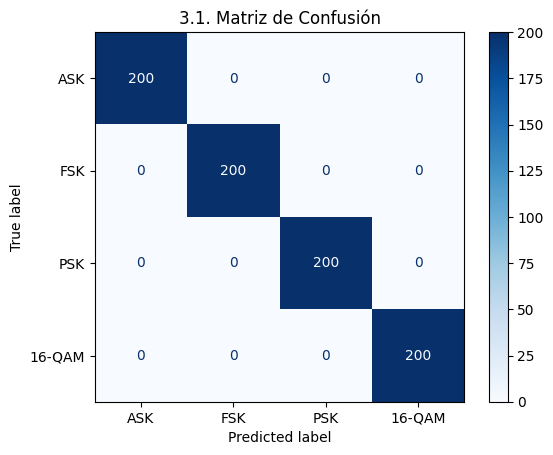

              precision    recall  f1-score   support

         ASK     1.0000    1.0000    1.0000       200
         FSK     1.0000    1.0000    1.0000       200
         PSK     1.0000    1.0000    1.0000       200
      16-QAM     1.0000    1.0000    1.0000       200

    accuracy                         1.0000       800
   macro avg     1.0000    1.0000    1.0000       800
weighted avg     1.0000    1.0000    1.0000       800

SNR = -5 dB -> Precisión: 72.75%
SNR =  0 dB -> Precisión: 81.75%
SNR =  5 dB -> Precisión: 100.00%
SNR = 10 dB -> Precisión: 100.00%
SNR = 15 dB -> Precisión: 100.00%
SNR = 20 dB -> Precisión: 100.00%


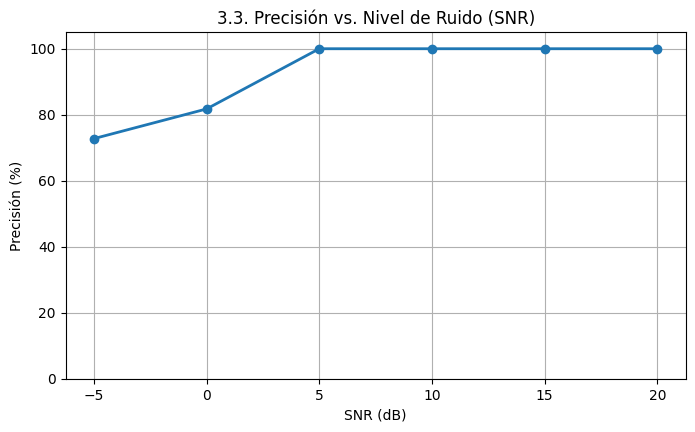


--- 3.4. Análisis de errores por modulación ---
ASK    -> Precisión: 100.00% | Errores: 0/200
FSK    -> Precisión: 100.00% | Errores: 0/200
PSK    -> Precisión: 100.00% | Errores: 0/200
16-QAM -> Precisión: 100.00% | Errores: 0/200


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import load_model, Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout

nombres_clases = ['ASK', 'FSK', 'PSK', '16-QAM']
f_s, f_c, R_s = 10000, 1000, 100
sps = int(f_s / R_s)

# Respaldo de seguridad: si la sesión de Colab se reinició y faltan 'model' o 'X_test',
# los reconstruye en memoria para que la Fase 3 corra sin frenarse[cite: 3, 4].
if 'X_test' not in locals() or 'y_test' not in locals():
    rng_base = np.random.default_rng(42)
    def _gen_bits(n): return rng_base.integers(0, 2, n)
    def _mod_ask(bits): return np.repeat(bits, sps) * np.cos(2 * np.pi * f_c * np.arange(len(bits) * sps) / f_s)
    def _mod_fsk(bits, df=200):
        out = []
        for b in bits:
            f = f_c + df if b == 1 else f_c - df
            out.extend(np.cos(2 * np.pi * f * np.linspace(0, sps / f_s, sps, endpoint=False)))
        return np.array(out)
    def _mod_psk(bits):
        out = []
        for b in bits:
            fase = 0 if b == 1 else np.pi
            out.extend(np.cos(2 * np.pi * f_c * np.linspace(0, sps / f_s, sps, endpoint=False) + fase))
        return np.array(out)
    def _mod_qam(s16):
        out = []
        for s in s16:
            iv, qv = ((s >> 2) & 0x03) - 1.5, (s & 0x03) - 1.5
            t = np.linspace(0, sps / f_s, sps, endpoint=False)
            out.extend(iv * np.cos(2 * np.pi * f_c * t) - qv * np.sin(2 * np.pi * f_c * t))
        return np.array(out)
    def _awgn(sig, snr):
        p_sig = np.mean(sig ** 2)
        return sig + rng_base.normal(0, np.sqrt(p_sig / (10 ** (snr / 10.0))), len(sig))
    def _fit_len(sig, obj=2000):
        return sig[:obj] if len(sig) > obj else np.pad(sig, (0, obj - len(sig)), 'constant')

    X_base, y_base = [], []
    for snr in [0, 5, 10, 15, 20]:
        for _ in range(200):
            gens = [
                lambda: _mod_ask(_gen_bits(20)),
                lambda: _mod_fsk(_gen_bits(20)),
                lambda: _mod_psk(_gen_bits(20)),
                lambda: _mod_qam(rng_base.integers(0, 16, 10))
            ]
            for idx, fn in enumerate(gens):
                s = _fit_len(fn(), 2000)
                X_base.append(s + _awgn(np.zeros(2000), snr))
                y_base.append(idx)

    X_base, y_base = np.array(X_base), np.array(y_base)
    X_train, X_test, y_train, y_test = train_test_split(
        X_base, y_base, test_size=0.20, random_state=42, stratify=y_base
    )

if 'model' not in locals():
    if os.path.exists('detector_modulaciones_cnn.keras'):
        model = load_model('detector_modulaciones_cnn.keras')
    else:
        model = Sequential([
            Conv1D(32, kernel_size=3, activation='relu', input_shape=(2000, 1)),
            MaxPooling1D(2),
            Conv1D(64, kernel_size=3, activation='relu'),
            MaxPooling1D(2),
            Flatten(),
            Dense(64, activation='relu'),
            Dropout(0.3),
            Dense(4, activation='softmax')
        ])
        model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        model.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_test, y_test), verbose=1)
        model.save('detector_modulaciones_cnn.keras')

# 3.1. Matriz de Confusión: Evalúa el modelo con el conjunto de prueba y genera
# una matriz de confusión para analizar si confunde ASK con PSK y por qué[cite: 3].
y_pred_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nombres_clases)
disp.plot(cmap='Blues')
plt.title('3.1. Matriz de Confusión')
plt.show()

print(classification_report(y_test, y_pred, target_names=nombres_clases, digits=4))

# 3.2. Prueba de estrés (Ruido): Alimenta al modelo con señales de prueba que
# tienen distintos niveles de ruido SNR (bajo, medio y alto)[cite: 3].
rng_eval = np.random.default_rng(123)
niveles_snr_eval = [-5, 0, 5, 10, 15, 20]
accuracies_snr = []

def gen_senal_limpia(clase_idx):
    if clase_idx == 0:
        bits = rng_eval.integers(0, 2, 20)
        sig = np.repeat(bits, sps) * np.cos(2 * np.pi * f_c * np.arange(len(bits) * sps) / f_s)
    elif clase_idx == 1:
        bits = rng_eval.integers(0, 2, 20)
        out = []
        for b in bits:
            f = f_c + 200 if b == 1 else f_c - 200
            out.extend(np.cos(2 * np.pi * f * np.linspace(0, sps / f_s, sps, endpoint=False)))
        sig = np.array(out)
    elif clase_idx == 2:
        bits = rng_eval.integers(0, 2, 20)
        out = []
        for b in bits:
            fase = 0 if b == 1 else np.pi
            out.extend(np.cos(2 * np.pi * f_c * np.linspace(0, sps / f_s, sps, endpoint=False) + fase))
        sig = np.array(out)
    else:
        s16 = rng_eval.integers(0, 16, 10)
        out = []
        for s in s16:
            iv, qv = ((s >> 2) & 0x03) - 1.5, (s & 0x03) - 1.5
            t = np.linspace(0, sps / f_s, sps, endpoint=False)
            out.extend(iv * np.cos(2 * np.pi * f_c * t) - qv * np.sin(2 * np.pi * f_c * t))
        sig = np.array(out)
    return sig[:2000] if len(sig) > 2000 else np.pad(sig, (0, 2000 - len(sig)), 'constant')

for snr in niveles_snr_eval:
    X_snr, y_snr = [], []
    for _ in range(100):
        for c in range(4):
            limpia = gen_senal_limpia(c)
            p_sig = np.mean(limpia ** 2)
            ruido = rng_eval.normal(0, np.sqrt(p_sig / (10 ** (snr / 10.0))), 2000)
            X_snr.append(limpia + ruido)
            y_snr.append(c)
    X_snr, y_snr = np.array(X_snr), np.array(y_snr)
    _, acc_snr = model.evaluate(X_snr, y_snr, verbose=0)
    accuracies_snr.append(acc_snr * 100)
    print(f"SNR = {snr:>2} dB -> Precisión: {acc_snr * 100:.2f}%")

# 3.3. Gráfica de rendimiento: Genera una gráfica con SNR en el eje X y precisión
# en el eje Y para observar en qué punto el modelo se vuelve "ciego" al ruido[cite: 3].
plt.figure(figsize=(8, 4.5))
plt.plot(niveles_snr_eval, accuracies_snr, marker='o', linewidth=2)
plt.title('3.3. Precisión vs. Nivel de Ruido (SNR)')
plt.xlabel('SNR (dB)')
plt.ylabel('Precisión (%)')
plt.ylim(0, 105)
plt.grid(True)
plt.show()

# 3.4. Análisis de errores: Identifica cuál de las 4 modulaciones (ASK, FSK, PSK,
# QAM) fue más difícil de clasificar para la IA[cite: 3].
print("\n--- 3.4. Análisis de errores por modulación ---")
for idx, nombre in enumerate(nombres_clases):
    mask = (y_test == idx)
    acc_clase = np.mean(y_pred[mask] == y_test[mask]) * 100
    errores_clase = np.sum(y_pred[mask] != y_test[mask])
    print(f"{nombre:<6} -> Precisión: {acc_clase:6.2f}% | Errores: {errores_clase}/{np.sum(mask)}")